# Sales Data Analysis Dashboard
**Data Analysis Internship Project**

**Goal:** Study the Superstore sales data to find out how much the business sells, when it sells most, which products, regions and categories perform best, and what the business can do about it.

**Tools:** Python, Pandas, NumPy, Matplotlib

**Notebook steps**
1. Load the data
2. Understand the data
3. Check data quality
4. Clean the data
5. Key numbers (Total Sales, Total Orders)
6. Monthly sales and trend
7. Top 10 products
8. Regional analysis
9. Category analysis
10. Business insights
11. Export data for the HTML dashboard

## 1. Import libraries and set up folders

In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Folder paths (the notebook lives in /notebooks, so we go one level up)
RAW_PATH = "../data/superstore_raw.csv"
CLEAN_PATH = "../data/superstore_cleaned.csv"
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
COLOR = "#1f6f8b"   # one main colour so every chart looks consistent

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()

## 2. Load the original dataset
The file is saved with a Windows (latin-1) encoding, so I pass `encoding='latin1'` to avoid a read error.

In [2]:
df_raw = pd.read_csv(RAW_PATH, encoding="latin1")
print("Rows:", df_raw.shape[0], "| Columns:", df_raw.shape[1])
df_raw.head()

Rows: 9994 | Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 3. Data understanding

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
df_raw.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50","55,190.38",229.86,3.79,0.16,28.66
std,"2,885.16","32,063.69",623.25,2.23,0.21,234.26
min,1.00,"1,040.00",0.44,1.00,0.00,"-6,599.98"
25%,"2,499.25","23,223.00",17.28,2.00,0.00,1.73
50%,"4,997.50","56,430.50",54.49,3.00,0.20,8.67
75%,"7,495.75","90,008.00",209.94,5.00,0.20,29.36
max,"9,994.00","99,301.00","22,638.48",14.00,0.80,"8,399.98"


In [5]:
# Number of unique values in the important text columns
for col in ["Order ID", "Customer ID", "Product ID", "Product Name", "Region", "Category", "Sub-Category"]:
    print(f"{col:15s} -> {df_raw[col].nunique()} unique values")

Order ID        -> 5009 unique values
Customer ID     -> 793 unique values
Product ID      -> 1862 unique values
Product Name    -> 1850 unique values
Region          -> 4 unique values
Category        -> 3 unique values
Sub-Category    -> 17 unique values


**What the columns mean (the ones I use most)**

| Column | Meaning |
|---|---|
| Order ID | Number of the order. One order can have several rows (one row per product) |
| Order Date | Date the order was placed |
| Region | East, West, Central or South |
| Category / Sub-Category | Furniture, Office Supplies, Technology and their sub groups |
| Product Name | Name of the product sold |
| Sales | Sales amount in dollars for that row |
| Profit | Profit for that row (can be negative) |

## 4. Data quality checks

In [6]:
# 4.1 Missing values
missing = df_raw.isnull().sum()
print("Total missing values:", missing.sum())
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [7]:
# 4.2 Exact duplicate rows
print("Exact duplicate rows:", df_raw.duplicated().sum())

# Row ID is just a counter (1, 2, 3 ...), so it makes every row look different.
# Let me check duplicates again after ignoring Row ID.
cols_without_rowid = [c for c in df_raw.columns if c != "Row ID"]
dup_mask = df_raw.duplicated(subset=cols_without_rowid, keep=False)
print("Rows that repeat when Row ID is ignored:", dup_mask.sum())
df_raw.loc[dup_mask, ["Row ID", "Order ID", "Order Date", "Product Name", "Sales", "Quantity"]]

Exact duplicate rows: 0
Rows that repeat when Row ID is ignored: 2


,Row ID,Order ID,Order Date,Product Name,Sales,Quantity
3405,3406,US-2014-150119,4/23/2014,Global Leather Highback Executive Chair with P...,281.37,2
3406,3407,US-2014-150119,4/23/2014,Global Leather Highback Executive Chair with P...,281.37,2


In [8]:
# 4.3 Extra spaces in text columns
text_cols = df_raw.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    n = (df_raw[col] != df_raw[col].str.strip()).sum()
    if n > 0:
        print(f"{col}: {n} values have extra spaces at the start/end")

Product Name: 16 values have extra spaces at the start/end


In [9]:
# 4.4 Logical checks
print("Rows with Sales <= 0:", (df_raw["Sales"] <= 0).sum())
print("Rows with Quantity <= 0:", (df_raw["Quantity"] <= 0).sum())
print("Rows with negative Profit (loss-making lines):", (df_raw["Profit"] < 0).sum())

order_date = pd.to_datetime(df_raw["Order Date"], format="%m/%d/%Y")
ship_date = pd.to_datetime(df_raw["Ship Date"], format="%m/%d/%Y")
print("Rows shipped before they were ordered:", (ship_date < order_date).sum())
print("Date range:", order_date.min().date(), "to", order_date.max().date())

Rows with Sales <= 0: 0
Rows with Quantity <= 0: 0
Rows with negative Profit (loss-making lines): 1871
Rows shipped before they were ordered: 0
Date range: 2014-01-03 to 2017-12-30


**What the checks show**
- There are **no missing values** and no exact duplicate rows.
- If I ignore `Row ID`, **1 row is repeated** (same order, same product, same quantity), so I treat it as a duplicate and remove it.
- A few product names have extra spaces at the end, which could split one product into two groups, so I strip the spaces.
- Sales and quantity are always positive, and no order ships before it is placed.

## 5. Data cleaning

In [10]:
df = df_raw.copy()

# 5.1 Remove extra spaces from text columns
for col in text_cols:
    df[col] = df[col].str.strip()

# 5.2 Convert date columns from text to real dates
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# 5.3 Remove duplicates (ignoring the Row ID counter)
before = len(df)
df = df.drop_duplicates(subset=cols_without_rowid, keep="first")
print("Duplicate rows removed:", before - len(df))

# 5.4 Handle missing values
# This dataset has none, but I keep the code so the notebook also works if the file changes.
key_cols = ["Order ID", "Order Date", "Region", "Category", "Product Name", "Sales"]
before = len(df)
df = df.dropna(subset=key_cols)                      # rows missing key fields are dropped
print("Rows dropped for missing key fields:", before - len(df))
df["Profit"] = df["Profit"].fillna(df["Profit"].median())   # numeric gap -> median
df["Discount"] = df["Discount"].fillna(0)                   # no discount info -> 0

# 5.5 Add helper columns for time analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)

df.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH)

Duplicate rows removed: 1
Rows dropped for missing key fields: 0


Missing values after cleaning: 0
Shape after cleaning: (9993, 25)


Saved: ../data/superstore_cleaned.csv


## 6. Key numbers: Total Sales and Total Orders

In [11]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()      # one order can have many rows, so count unique Order IDs
total_lines = len(df)
total_profit = df["Profit"].sum()
avg_order_value = total_sales / total_orders

print(f"Total Sales        : ${total_sales:,.2f}")
print(f"Total Orders       : {total_orders:,}")
print(f"Order lines (rows) : {total_lines:,}")
print(f"Average order value: ${avg_order_value:,.2f}")
print(f"Total Profit       : ${total_profit:,.2f}  (margin {total_profit/total_sales:.1%})")

Total Sales        : $2,296,919.49
Total Orders       : 5,009
Order lines (rows) : 9,993
Average order value: $458.56
Total Profit       : $286,409.08  (margin 12.5%)


## 7. Monthly sales analysis and trend

In [12]:
monthly = df.groupby("Year-Month").agg(Sales=("Sales", "sum"), Orders=("Order ID", "nunique"))
monthly["3-Month Avg"] = monthly["Sales"].rolling(3).mean()   # smooths out the ups and downs
monthly.head(12)

,Sales,Orders,3-Month Avg
Year-Month,,,
2014-01,"14,236.90",32,NaN
2014-02,"4,519.89",28,NaN
2014-03,"55,691.01",71,"24,815.93"
2014-04,"28,013.97",66,"29,408.29"
2014-05,"23,648.29",69,"35,784.42"
2014-06,"34,595.13",66,"28,752.46"
2014-07,"33,946.39",65,"30,729.94"
2014-08,"27,909.47",72,"32,150.33"
2014-09,"81,777.35",130,"47,877.74"


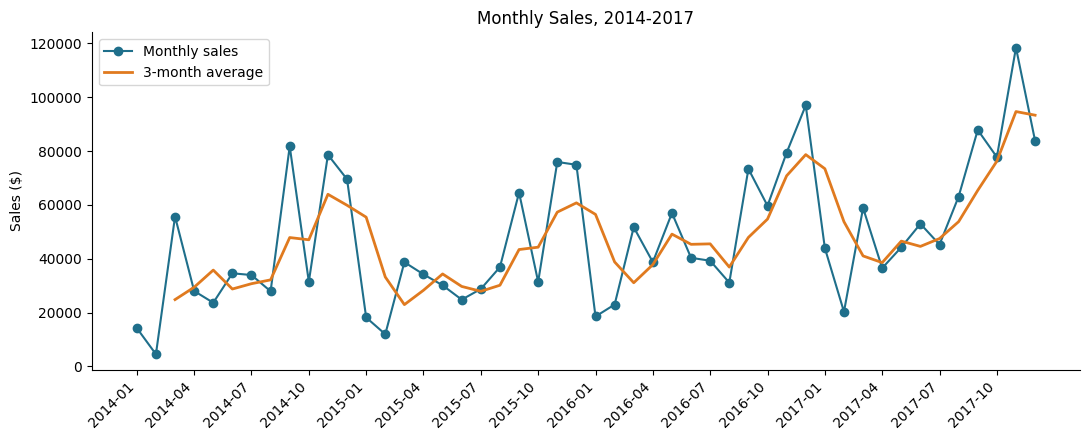

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Sales"], marker="o", color=COLOR, label="Monthly sales")
ax.plot(monthly.index, monthly["3-Month Avg"], color="#e07a1f", linewidth=2, label="3-month average")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
ax.set_title("Monthly Sales, 2014-2017")
ax.set_ylabel("Sales ($)")
ax.legend()
save_fig("01_monthly_sales_trend")

In [14]:
# Best and worst months, and a simple straight-line trend using NumPy
best_month = monthly["Sales"].idxmax()
worst_month = monthly["Sales"].idxmin()
print(f"Best month : {best_month}  (${monthly['Sales'].max():,.2f})")
print(f"Worst month: {worst_month}  (${monthly['Sales'].min():,.2f})")

x = np.arange(len(monthly))
slope, intercept = np.polyfit(x, monthly["Sales"].values, 1)
print(f"Trend line: sales change by about ${slope:,.0f} per month on average")

Best month : 2017-11  ($118,447.82)
Worst month: 2014-02  ($4,519.89)
Trend line: sales change by about $903 per month on average


          Sales  Growth %
Year                     
2014 483,966.13       NaN
2015 470,532.51     -2.78
2016 609,205.60     29.47
2017 733,215.26     20.36


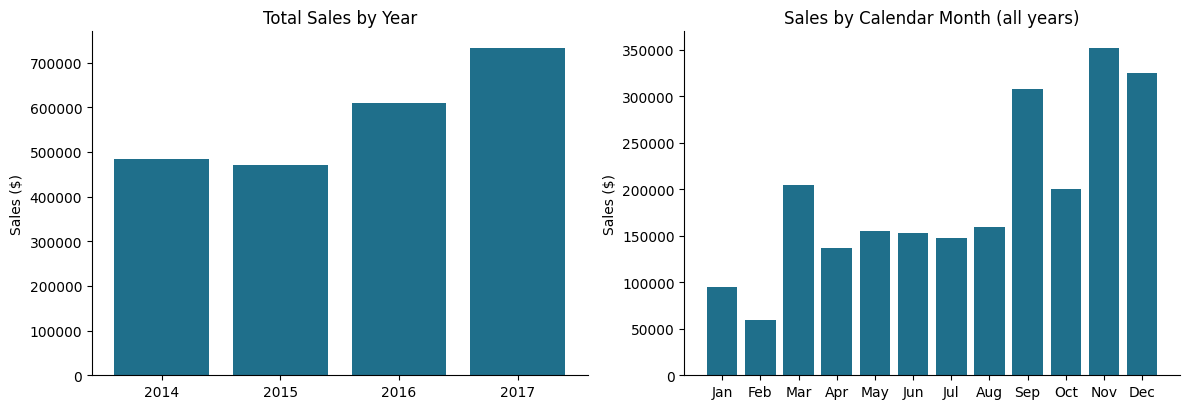

In [15]:
# Yearly totals and growth
yearly = df.groupby("Year")["Sales"].sum()
yearly_growth = yearly.pct_change() * 100
print(pd.DataFrame({"Sales": yearly, "Growth %": yearly_growth}))

# Which calendar months are strongest? (all years added together)
by_month = df.groupby(["Month", "Month Name"])["Sales"].sum().reset_index().sort_values("Month")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(yearly.index.astype(str), yearly.values, color=COLOR)
axes[0].set_title("Total Sales by Year")
axes[0].set_ylabel("Sales ($)")
axes[1].bar(by_month["Month Name"], by_month["Sales"], color=COLOR)
axes[1].set_title("Sales by Calendar Month (all years)")
axes[1].set_ylabel("Sales ($)")
save_fig("02_yearly_and_seasonal_sales")

In [16]:
# Share of sales that comes from the last 3 months of the year
q4_share = by_month[by_month["Month"] >= 10]["Sales"].sum() / by_month["Sales"].sum()
print(f"Oct-Dec share of total sales: {q4_share:.1%}")
by_month.sort_values("Sales", ascending=False).head(5)

Oct-Dec share of total sales: 38.2%


,Month,Month Name,Sales
10,11,Nov,"352,461.07"
11,12,Dec,"325,293.50"
8,9,Sep,"307,649.95"
2,3,Mar,"205,005.49"
9,10,Oct,"200,322.98"


## 8. Top 10 products

In [17]:
top_products = (df.groupby("Product Name")
                  .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
                  .sort_values("Sales", ascending=False)
                  .head(10))
top_products

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38","7,753.04",31
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6
HON 5400 Series Task Chairs for Big and Tall,"21,870.58",0.00,39
GBC DocuBind TL300 Electric Binding System,"19,823.48","2,233.51",37
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",760.98,48
Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90","4,094.98",12
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27


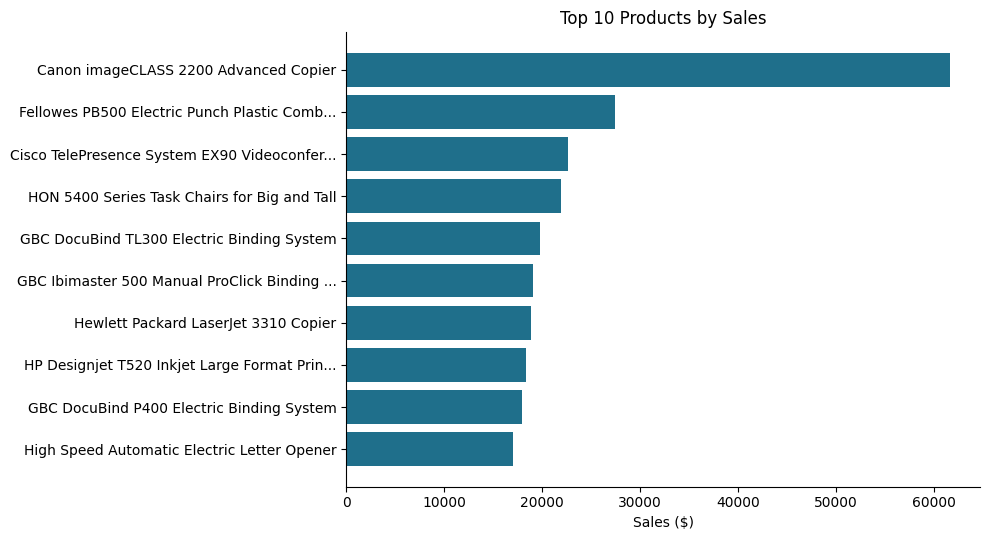

Top 10 products = 10.6% of all sales
Top 10 products with negative profit: ['Cisco TelePresence System EX90 Videoconferencing Unit', 'GBC DocuBind P400 Electric Binding System', 'High Speed Automatic Electric Letter Opener']


In [18]:
fig, ax = plt.subplots(figsize=(10, 5.5))
labels = [n if len(n) <= 45 else n[:42] + "..." for n in top_products.index]
ax.barh(labels[::-1], top_products["Sales"].values[::-1], color=COLOR)
ax.set_title("Top 10 Products by Sales")
ax.set_xlabel("Sales ($)")
save_fig("03_top10_products")

print(f"Top 10 products = {top_products['Sales'].sum()/total_sales:.1%} of all sales")
print("Top 10 products with negative profit:", list(top_products[top_products['Profit'] < 0].index))

## 9. Regional sales analysis

In [19]:
region = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
region["Sales Share %"] = region["Sales"] / region["Sales"].sum() * 100
region["Profit Margin %"] = region["Profit"] / region["Sales"] * 100
region = region.sort_values("Sales", ascending=False)
region

,Sales,Profit,Orders,Sales Share %,Profit Margin %
Region,,,,,
West,"725,457.82","108,418.45",1611,31.58,14.94
East,"678,499.87","91,534.84",1401,29.54,13.49
Central,"501,239.89","39,706.36",1175,21.82,7.92
South,"391,721.91","46,749.43",822,17.05,11.93


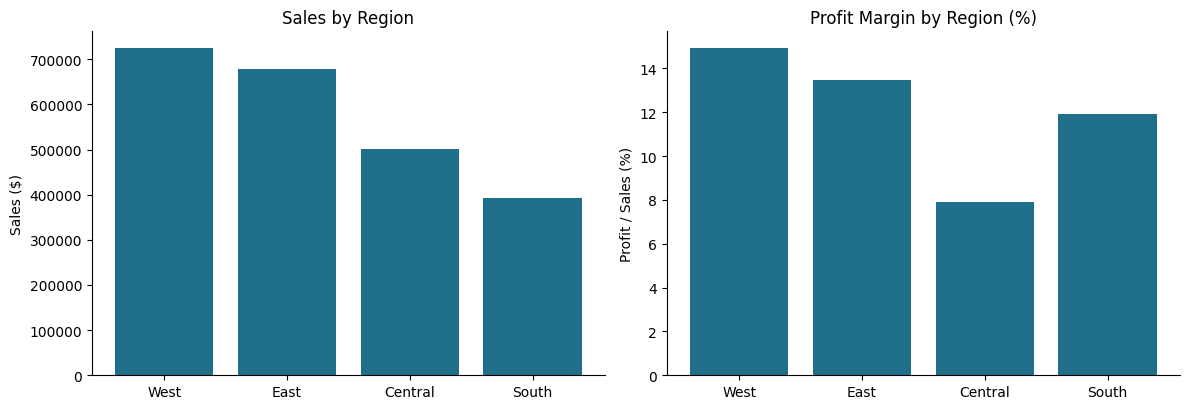

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(region.index, region["Sales"], color=COLOR)
axes[0].set_title("Sales by Region")
axes[0].set_ylabel("Sales ($)")
bar_colors = [COLOR if v >= 0 else "#c0392b" for v in region["Profit Margin %"]]
axes[1].bar(region.index, region["Profit Margin %"], color=bar_colors)
axes[1].set_title("Profit Margin by Region (%)")
axes[1].set_ylabel("Profit / Sales (%)")
save_fig("04_regional_analysis")

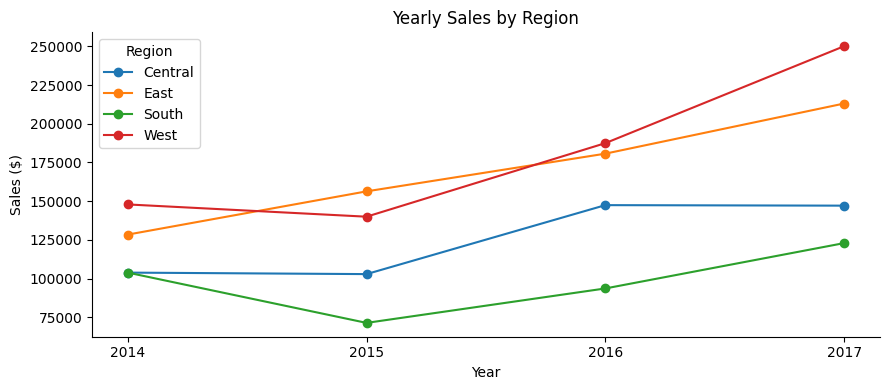

Region,Central,East,South,West
Year,,,,
2014,"103,838.16","128,399.09","103,845.84","147,883.03"
2015,"102,874.22","156,332.06","71,359.98","139,966.25"
2016,"147,429.38","180,685.82","93,610.22","187,480.18"
2017,"147,098.13","213,082.90","122,905.86","250,128.37"


In [21]:
# Region by year: is any region growing faster than the others?
region_year = df.pivot_table(index="Year", columns="Region", values="Sales", aggfunc="sum")
region_year.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Yearly Sales by Region")
plt.ylabel("Sales ($)")
plt.xticks(region_year.index)
save_fig("05_region_by_year")
region_year

## 10. Category analysis

In [22]:
category = df.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
category["Sales Share %"] = category["Sales"] / category["Sales"].sum() * 100
category["Profit Margin %"] = category["Profit"] / category["Sales"] * 100
category = category.sort_values("Sales", ascending=False)
category

,Sales,Profit,Quantity,Sales Share %,Profit Margin %
Category,,,,,
Technology,"836,154.03","145,454.95",6939,36.40,17.40
Furniture,"741,718.42","18,463.33",8026,32.29,2.49
Office Supplies,"719,047.03","122,490.80",22906,31.30,17.04


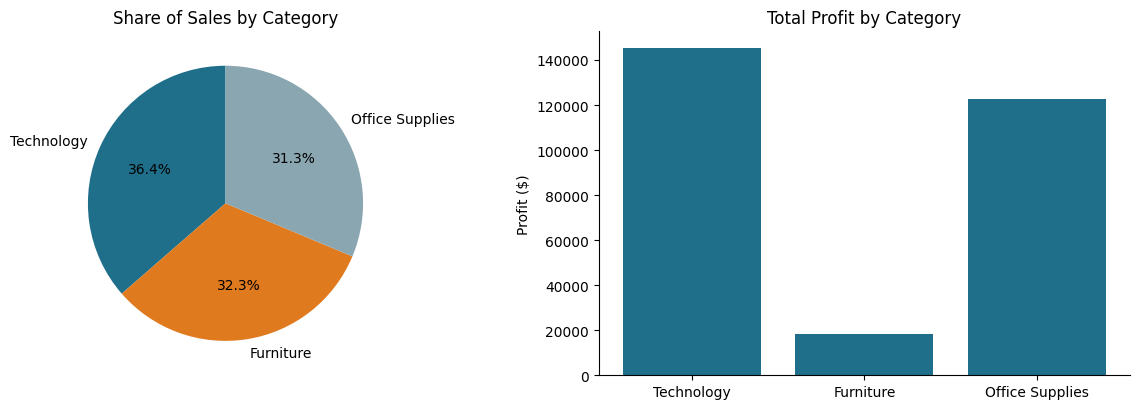

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].pie(category["Sales"], labels=category.index, autopct="%1.1f%%", startangle=90,
            colors=["#1f6f8b", "#e07a1f", "#8aa6b1"])
axes[0].set_title("Share of Sales by Category")
axes[1].bar(category.index, category["Profit"], color=COLOR)
axes[1].set_title("Total Profit by Category")
axes[1].set_ylabel("Profit ($)")
save_fig("06_category_analysis")

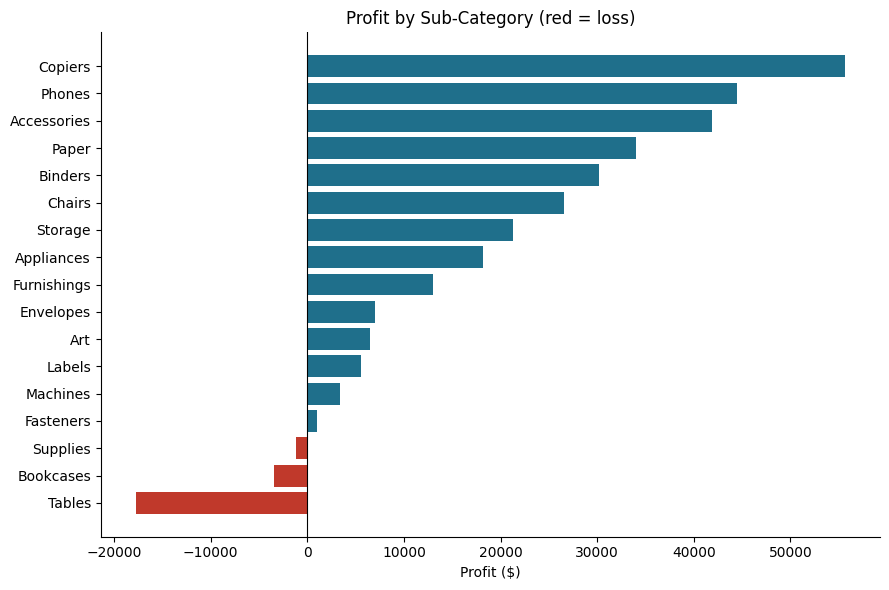

,Sales,Profit
Sub-Category,,
Tables,"206,965.53","-17,725.48"
Bookcases,"114,880.00","-3,472.56"
Supplies,"46,673.54","-1,189.10"
Fasteners,"3,024.28",949.52


In [24]:
# Sub-categories: which ones lose money?
sub = (df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
         .sort_values("Profit"))
colors = ["#c0392b" if p < 0 else COLOR for p in sub["Profit"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub["Profit"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Profit by Sub-Category (red = loss)")
ax.set_xlabel("Profit ($)")
save_fig("07_subcategory_profit")
sub.sort_values("Profit").head(4)

                      Sales     Profit  Rows  Profit Margin %
Discount Group                                               
No discount    1,087,908.47 320,987.60  4798            29.51
Up to 20%        846,522.24 100,785.47  3803            11.91
21-40%           233,856.53 -35,805.41   459           -15.31
Over 40%         128,632.25 -99,558.59   933           -77.40


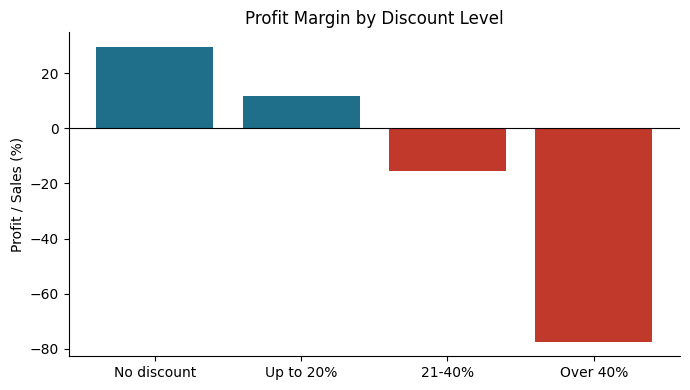

In [25]:
# Does discounting hurt profit? Compare profit margin by discount level
df["Discount Group"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
                              labels=["No discount", "Up to 20%", "21-40%", "Over 40%"])
disc = df.groupby("Discount Group", observed=True).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Rows=("Sales", "size"))
disc["Profit Margin %"] = disc["Profit"] / disc["Sales"] * 100
print(disc)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(disc.index.astype(str), disc["Profit Margin %"], color=["#1f6f8b", "#1f6f8b", "#c0392b", "#c0392b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit Margin by Discount Level")
ax.set_ylabel("Profit / Sales (%)")
save_fig("08_discount_vs_margin")

## 11. Business insights (calculated from the data)

In [26]:
top_region = region.index[0]
low_margin_region = region["Profit Margin %"].idxmin()
top_cat = category.index[0]
best_margin_cat = category["Profit Margin %"].idxmax()
loss_subs = sub[sub["Profit"] < 0]
best_calendar_month = by_month.loc[by_month["Sales"].idxmax(), "Month Name"]

insights = [
    f"1. Sales went from ${yearly.iloc[0]:,.0f} in {yearly.index[0]} to ${yearly.iloc[-1]:,.0f} in {yearly.index[-1]} (2015 dipped slightly, then 2016 and 2017 grew strongly).",
    f"2. Sales are seasonal: Oct-Dec produce {q4_share:.1%} of all sales and {best_calendar_month} is the strongest calendar month.",
    f"3. {top_region} is the largest region ({region.loc[top_region, 'Sales Share %']:.1f}% of sales).",
    f"4. {low_margin_region} has the lowest profit margin ({region.loc[low_margin_region, 'Profit Margin %']:.1f}%).",
    f"5. {top_cat} is the biggest category ({category.loc[top_cat, 'Sales Share %']:.1f}% of sales); {best_margin_cat} has the best profit margin ({category.loc[best_margin_cat, 'Profit Margin %']:.1f}%) and {category['Profit Margin %'].idxmin()} the lowest ({category['Profit Margin %'].min():.1f}%).",
    f"6. {len(loss_subs)} sub-categories lose money: {', '.join(loss_subs.index)}.",
    f"7. Discount levels of 21-40% give a margin of {disc.loc['21-40%', 'Profit Margin %']:.1f}% and over 40% give {disc.loc['Over 40%', 'Profit Margin %']:.1f}%.",
    f"8. The 10 best-selling products make up only {top_products['Sales'].sum()/total_sales:.1%} of sales, so sales are spread widely.",
]
for line in insights:
    print(line)

1. Sales went from $483,966 in 2014 to $733,215 in 2017 (2015 dipped slightly, then 2016 and 2017 grew strongly).
2. Sales are seasonal: Oct-Dec produce 38.2% of all sales and Nov is the strongest calendar month.
3. West is the largest region (31.6% of sales).
4. Central has the lowest profit margin (7.9%).
5. Technology is the biggest category (36.4% of sales); Technology has the best profit margin (17.4%) and Furniture the lowest (2.5%).
6. 3 sub-categories lose money: Tables, Bookcases, Supplies.
7. Discount levels of 21-40% give a margin of -15.3% and over 40% give -77.4%.
8. The 10 best-selling products make up only 10.6% of sales, so sales are spread widely.


## 12. Export data for the HTML dashboard
The dashboard needs to filter by year, region and category, so I save a compact version of the cleaned data (one small list per order line) in `dashboard/data.js`.

In [27]:
def codes(series):
    # turns text values into numbers (0, 1, 2 ...) to keep the file small
    values = sorted(series.unique())
    return values, series.map({v: i for i, v in enumerate(values)}).tolist()

regions, region_codes = codes(df["Region"])
cats, cat_codes = codes(df["Category"])
products, product_codes = codes(df["Product Name"])
orders, order_codes = codes(df["Order ID"])

rows = list(zip(df["Year"].tolist(), df["Month"].tolist(), region_codes, cat_codes,
                product_codes, order_codes,
                df["Sales"].round(2).tolist(), df["Profit"].round(2).tolist()))

data = {"regions": regions, "categories": cats, "products": products,
        "columns": ["year", "month", "region", "category", "product", "order", "sales", "profit"],
        "rows": rows}

with open("../dashboard/data.js", "w") as f:
    f.write("const DASHBOARD_DATA = " + json.dumps(data, separators=(",", ":")) + ";")

print("dashboard/data.js written with", len(rows), "rows")

dashboard/data.js written with 9993 rows


## 13. Conclusion
The analysis covers every step: loading, checking, cleaning, calculating and visualising the data. The charts are saved in `reports/figures/` and the interactive version is in `dashboard/index.html`.

**Limitations:** the data covers only four years, it is a sample dataset (not a real company's live data), and I did not test whether the patterns are statistically significant.